In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [19]:
data_1 = "Datasets/1P/1P_1_0/SPECTRA_000.hdf5"
data_2 = "Datasets/1P/1P_1_0/SPECTRA_015.hdf5"
data_3 = "Datasets/1P/1P_1_0/SPECTRA_030.hdf5"

In [36]:
with h5py.File(data_1, "r") as f_1:
    tau_1 = f_1["tau/H/1/1215"][:]
    colden_1 = f_1["colden/H/1"][:]
    header_1 = dict(f_1["Header"].attrs)

with h5py.File(data_2, "r") as f_2:
    tau_2 = f_2["tau/H/1/1215"][:]
    colden_2 = f_2["colden/H/1"][:]
    header_2 = dict(f_2["Header"].attrs)

with h5py.File(data_3, "r") as f_3:
    tau_3 =  f_3["tau/H/1/1215"][:]
    colden_3 = f_3["colden/H/1"][:]
    header_3 = dict(f_3["Header"].attrs)

In [37]:
print(f"Redshift dataset 1: {header_1.get("redshift"):.2e}")
print(f"Redshift dataset 2: {header_2.get("redshift"):.2e}")
print(f"Redshift dataset 3: {header_3.get("redshift"):.2e}")

Redshift dataset 1: 5.99e+00
Redshift dataset 2: 1.36e+00
Redshift dataset 3: 1.54e-01


In [77]:
def flux(tau):
    return np.exp(-tau)

def log(x):
    return np.log10(x);

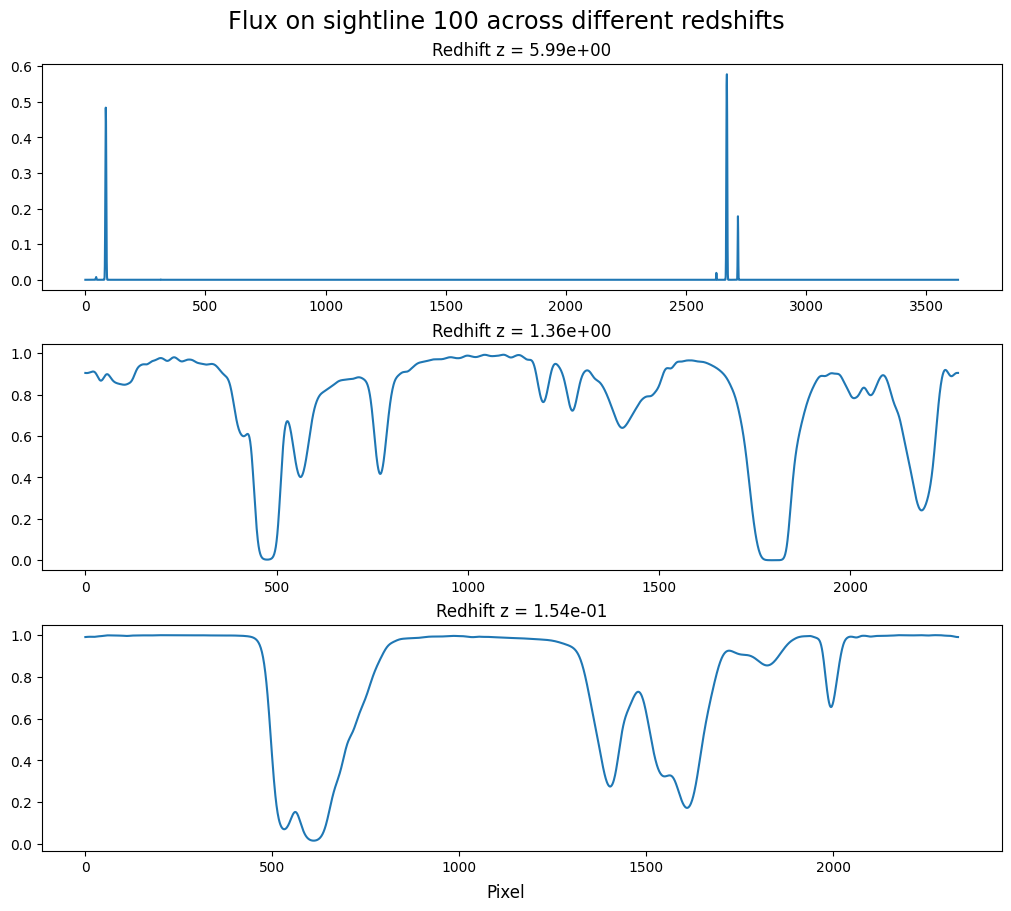

In [84]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)
sightline = 100

ax[0].plot(flux(tau_1)[sightline])
ax[1].plot(flux(tau_2)[sightline])
ax[2].plot(flux(tau_3)[sightline])

ax[0].set_title(f"Redhift z = {header_1.get("redshift"):.2e}", fontsize = "large")
ax[1].set_title(f"Redhift z = {header_2.get("redshift"):.2e}", fontsize = "large")
ax[2].set_title(f"Redhift z = {header_3.get("redshift"):.2e}", fontsize = "large")

fig.suptitle(f"Flux on sightline {sightline} across different redshifts", fontsize = "xx-large")
fig.supxlabel("Pixel")

plt.show()

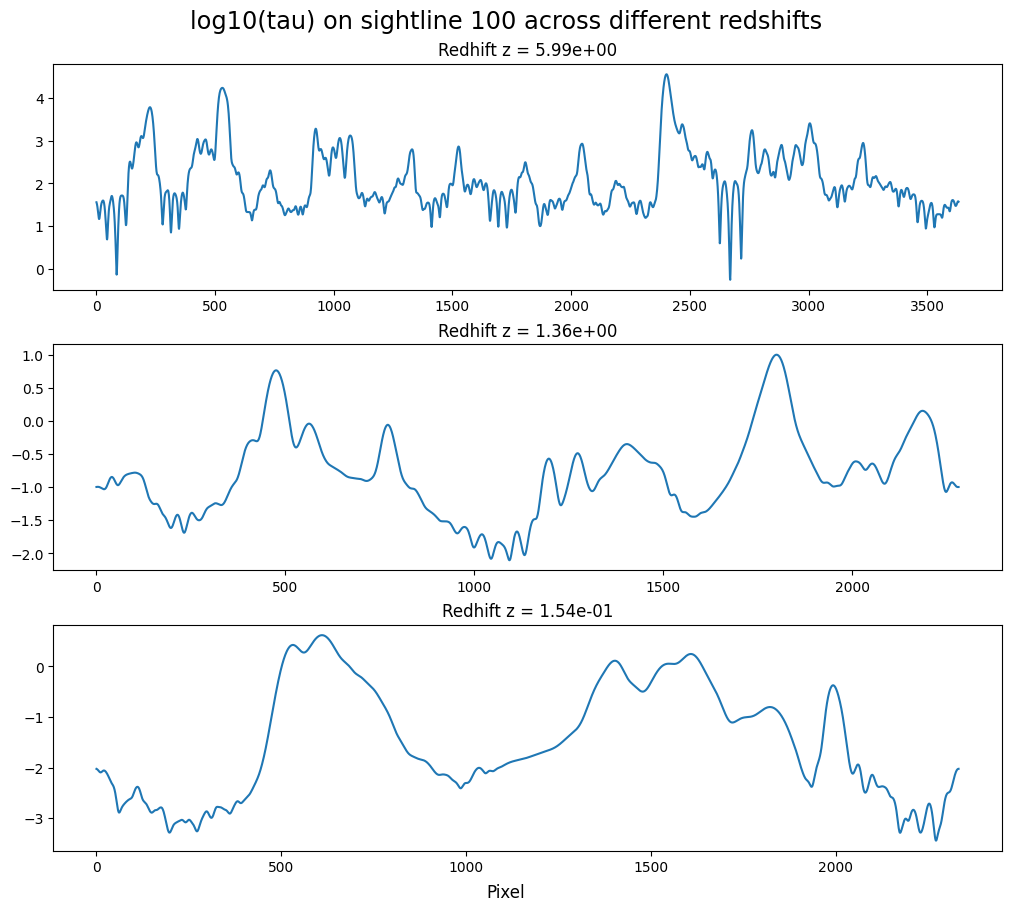

In [86]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)

ax[0].plot(log(tau_1)[sightline])
ax[1].plot(log(tau_2)[sightline])
ax[2].plot(log(tau_3)[sightline])

ax[0].set_title(f"Redhift z = {header_1.get("redshift"):.2e}", fontsize = "large")
ax[1].set_title(f"Redhift z = {header_2.get("redshift"):.2e}", fontsize = "large")
ax[2].set_title(f"Redhift z = {header_3.get("redshift"):.2e}", fontsize = "large")

fig.suptitle(f"log10(tau) on sightline {sightline} across different redshifts", fontsize = "xx-large")
fig.supxlabel("Pixel")

plt.show()

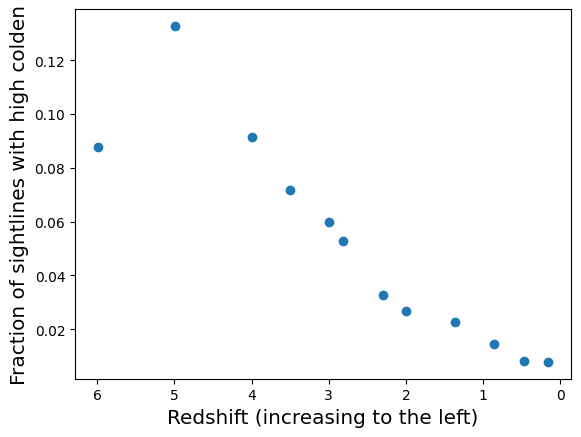

In [135]:
z_list = []
highN_list = []
snapshots = ["Datasets/1P/1P_1_0/SPECTRA_000.hdf5", "Datasets/1P/1P_1_0/SPECTRA_001.hdf5", "Datasets/1P/1P_1_0/SPECTRA_002.hdf5", 
             "Datasets/1P/1P_1_0/SPECTRA_003.hdf5", "Datasets/1P/1P_1_0/SPECTRA_004.hdf5", "Datasets/1P/1P_1_0/SPECTRA_005.hdf5", 
             "Datasets/1P/1P_1_0/SPECTRA_008.hdf5", "Datasets/1P/1P_1_0/SPECTRA_010.hdf5", "Datasets/1P/1P_1_0/SPECTRA_015.hdf5", 
             "Datasets/1P/1P_1_0/SPECTRA_020.hdf5", "Datasets/1P/1P_1_0/SPECTRA_025.hdf5", "Datasets/1P/1P_1_0/SPECTRA_030.hdf5"]

for s in snapshots:
    with h5py.File(s, "r") as f:
        colden = f["colden/H/1"][:]
        header = dict(f["Header"].attrs)
    z_list.append(header.get("redshift"))
    highN_list.append((np.sum(log(np.max(colden, axis = 1)) > 17)) / 5000)

fig, ax = plt.subplots()

ax.scatter(z_list, highN_list)
ax.set_xlabel("Redshift (increasing to the left)", fontsize = "x-large")
ax.set_ylabel("Fraction of sightlines with high colden", fontsize = "x-large")

ax.invert_xaxis()